# Minería de Datos — Actividad LOF e Isolation Forest

**Semana 11 · 27 de octubre de 2026 · Semestre VII**

Adaptación del notebook de clase `class_anomalias.ipynb`: conservamos el uso de **`LOF` e `IForest` de PyOD**, el patrón `fit → labels_ → decision_scores_` y la visualización con Matplotlib. Sustituimos los datos sintéticos por los archivos de la actividad.

**Objetivos:** detectar bots en SaaS con LOF (densidades locales diferentes), detectar fraudes en Ecommerce con Isolation Forest, medir falsos positivos y comparar cada predicción con la columna de verdad. También ordenar los **5 ejemplos con mayor score por categoría real** de fraude.

> Los CSV originales se leen de `data/mineria_de_datos/`. Las columnas `Tipo_Real` y `Etiqueta_Real` **no** se usan para entrenar; sirven únicamente para evaluar después. Los parámetros `contamination` son supuestos del ejercicio y no una estimación independiente de la prevalencia real.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.preprocessing import StandardScaler

# Misma API usada en class_anomalias.ipynb.
try:
    from pyod.models.iforest import IForest
    from pyod.models.lof import LOF
    implementacion = "PyOD"
except ModuleNotFoundError:
    # Respaldo para ejecutar este notebook fuera del entorno uv del repositorio.
    # Conserva las etiquetas y el orden de los scores de los detectores de sklearn
    # en los que se apoyan LOF e IForest. Los valores numéricos pueden variar con PyOD.
    from sklearn.ensemble import IsolationForest
    from sklearn.neighbors import LocalOutlierFactor

    class LOF:
        def __init__(self, n_neighbors=20, contamination=0.1):
            self.n_neighbors = n_neighbors
            self.contamination = contamination

        def fit(self, X):
            modelo = LocalOutlierFactor(n_neighbors=self.n_neighbors,
                                       contamination=self.contamination)
            modelo.fit(X)
            self.decision_scores_ = -modelo.negative_outlier_factor_
            self.threshold_ = np.percentile(self.decision_scores_,
                                            100 * (1 - self.contamination))
            self.labels_ = (self.decision_scores_ > self.threshold_).astype(int)
            return self

    class IForest:
        def __init__(self, n_estimators=100, contamination=0.1, random_state=None):
            self.n_estimators = n_estimators
            self.contamination = contamination
            self.random_state = random_state

        def fit(self, X):
            modelo = IsolationForest(n_estimators=self.n_estimators,
                                     contamination=self.contamination,
                                     random_state=self.random_state)
            modelo.fit(X)
            self.decision_scores_ = -modelo.score_samples(X)
            self.threshold_ = np.percentile(self.decision_scores_,
                                            100 * (1 - self.contamination))
            self.labels_ = (self.decision_scores_ > self.threshold_).astype(int)
            return self

    implementacion = "scikit-learn (respaldo equivalente; PyOD no disponible en este entorno)"

print(f"Implementación utilizada: {implementacion}")

Implementación utilizada: scikit-learn (respaldo equivalente; PyOD no disponible en este entorno)


In [2]:
# Ruta del repositorio, independientemente de dónde se abra el notebook.
try:
    from semestre_vii.mineria_de_datos import DATA_DIR
except ModuleNotFoundError:
    DATA_DIR = next(
        (carpeta / "data" / "mineria_de_datos"
         for carpeta in (Path.cwd(), *Path.cwd().parents)
         if (carpeta / "data" / "mineria_de_datos").is_dir()),
        None,
    )
    if DATA_DIR is None:
        raise FileNotFoundError("No encuentro data/mineria_de_datos desde la carpeta actual")

# Referencias a los CSV originales.
path_saas = DATA_DIR / "saas_anomalias.csv"
path_ecommerce = DATA_DIR / "ecommerce.csv"
df_saas = pd.read_csv(path_saas)
df_ecommerce = pd.read_csv(path_ecommerce)

print("SaaS:", df_saas.shape, "| Ecommerce:", df_ecommerce.shape)
print("Etiquetas SaaS:", df_saas["Tipo_Real"].value_counts().to_dict())
print("Etiquetas Ecommerce:", df_ecommerce["Etiqueta_Real"].value_counts().to_dict())
display(df_saas.head(3))
display(df_ecommerce.head(3))

SaaS: (10000, 3) | Ecommerce: (10000, 5)
Etiquetas SaaS: {'Plan_Gratuito': 9000, 'Plan_Enterprise': 979, 'Bot_Abuso_Inyectado': 21}
Etiquetas Ecommerce: {'Normal': 9970, 'Fraude_BotVeloz': 10, 'Fraude_Cupones': 10, 'Fraude_Triangulacion': 10}


,Monto_Gastado,Frecuencia_Consultas,Tipo_Real
0,45.63,12,Plan_Gratuito
1,52.68,7,Plan_Gratuito
2,460.75,102,Plan_Enterprise


,Cantidad_Articulos,Monto_Compra,Distancia_Envio_Km,Tiempo_En_Sitio_Seg,Etiqueta_Real
0,13,491.17,219.5,1785,Normal
1,13,490.99,109.4,1938,Normal
2,12,459.91,97.4,1608,Normal


## 1. SaaS: Local Outlier Factor (LOF)

Tenemos clientes Retail muy concentrados y clientes Enterprise legítimos en una región mucho más dispersa. **LOF compara densidades locales**, por lo que resulta más apropiado para este caso.

Se aplica `StandardScaler` como lo pide el profesor. Utilizamos **50 vecinos**: en estos datos, los 25 vecinos del ejemplo de clase producen muchos falsos positivos. La contaminación se fija en 0.21 % como supuesto del ejercicio.

In [3]:
contaminacion_saas = 0.0021
columnas_saas = ["Monto_Gastado", "Frecuencia_Consultas"]

X_datos = df_saas[columnas_saas].to_numpy()
escalador = StandardScaler()
X_scalado = escalador.fit_transform(X_datos)

# Entrenamiento LOF (estructura del notebook de clase).
clt_lof = LOF(n_neighbors=50, contamination=contaminacion_saas)
clt_lof.fit(X_scalado)

df_saas["lof_Labels"] = clt_lof.labels_
df_saas["lof_Scores"] = clt_lof.decision_scores_

# La etiqueta real NO participó en el entrenamiento.
df_saas["Real_Anomalia"] = (df_saas["Tipo_Real"] == "Bot_Abuso_Inyectado").astype(int)

def comparar_predicciones(df, etiqueta_predicha):
    real = df["Real_Anomalia"].eq(1)
    pred = df[etiqueta_predicha].eq(1)
    return pd.Series({
        "Registros": len(df),
        "Anomalías reales": int(real.sum()),
        "Anomalías detectadas": int(pred.sum()),
        "Verdaderos positivos": int((real & pred).sum()),
        "Falsos positivos": int((~real & pred).sum()),
        "Falsos negativos": int((real & ~pred).sum()),
        "Verdaderos negativos": int((~real & ~pred).sum()),
    })

resumen_saas = comparar_predicciones(df_saas, "lof_Labels")
print("--------- RESUMEN SAAS / LOF ---------")
print(f"Umbral LOF: {clt_lof.threshold_:.8f}")
display(resumen_saas.to_frame(name="Valor"))

--------- RESUMEN SAAS / LOF ---------
Umbral LOF: 4.32505370


,Valor
Registros,10000
Anomalías reales,21
Anomalías detectadas,21
Verdaderos positivos,19
Falsos positivos,2
Falsos negativos,2
Verdaderos negativos,9977


In [4]:
df_saas["Comparacion"] = np.select(
    [
        df_saas["lof_Labels"].eq(1) & df_saas["Real_Anomalia"].eq(1),
        df_saas["lof_Labels"].eq(1) & df_saas["Real_Anomalia"].eq(0),
        df_saas["lof_Labels"].eq(0) & df_saas["Real_Anomalia"].eq(1),
    ],
    ["Verdadero positivo", "Falso positivo", "Falso negativo"],
    default="Verdadero negativo",
)

print("Registros marcados como anomalía (ordenados por score, mayor = más anómalo):")
columnas_reporte_saas = columnas_saas + ["Tipo_Real", "lof_Labels", "lof_Scores", "Comparacion"]
display(
    df_saas.loc[df_saas["lof_Labels"].eq(1), columnas_reporte_saas]
    .sort_values("lof_Scores", ascending=False)
)

print("Bots reales que no fueron detectados:")
display(df_saas.loc[df_saas["Comparacion"].eq("Falso negativo"), columnas_reporte_saas])

Registros marcados como anomalía (ordenados por score, mayor = más anómalo):


,Monto_Gastado,Frecuencia_Consultas,Tipo_Real,lof_Labels,lof_Scores,Comparacion
6218,73.35,23,Bot_Abuso_Inyectado,1,6.210531,Verdadero positivo
6511,70.63,23,Bot_Abuso_Inyectado,1,6.160556,Verdadero positivo
9974,82.58,22,Bot_Abuso_Inyectado,1,5.998215,Verdadero positivo
8110,75.70,22,Bot_Abuso_Inyectado,1,5.809055,Verdadero positivo
7216,73.89,22,Bot_Abuso_Inyectado,1,5.766979,Verdadero positivo
9205,81.19,21,Bot_Abuso_Inyectado,1,5.658737,Verdadero positivo
2232,80.58,21,Bot_Abuso_Inyectado,1,5.639165,Verdadero positivo
4063,76.35,21,Bot_Abuso_Inyectado,1,5.417325,Verdadero positivo
7336,76.33,21,Bot_Abuso_Inyectado,1,5.416766,Verdadero positivo
9843,84.09,20,Bot_Abuso_Inyectado,1,5.394424,Verdadero positivo


Bots reales que no fueron detectados:


,Monto_Gastado,Frecuencia_Consultas,Tipo_Real,lof_Labels,lof_Scores,Comparacion
1847,70.91,18,Bot_Abuso_Inyectado,0,4.325028,Falso negativo
5922,70.71,18,Bot_Abuso_Inyectado,0,4.316912,Falso negativo


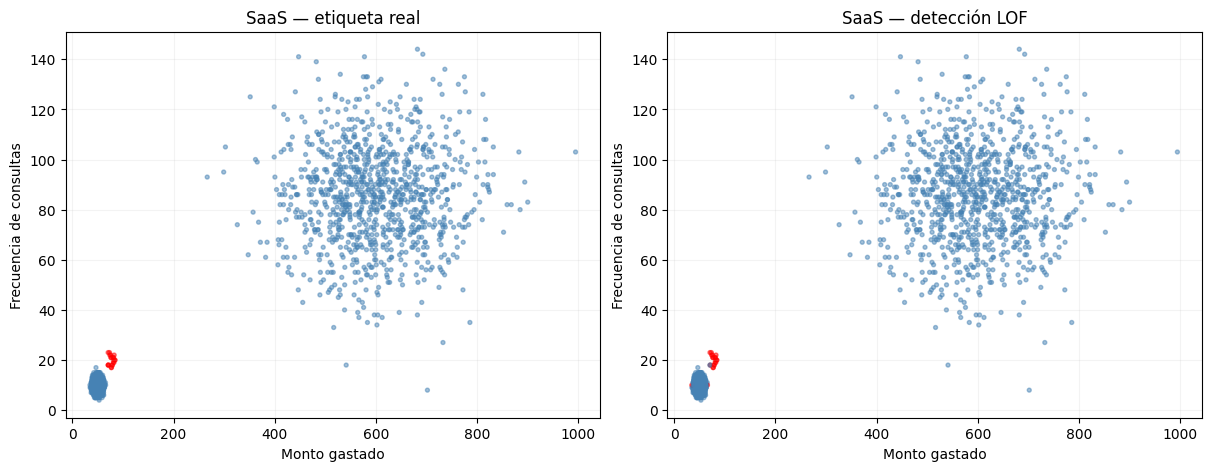

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained")

colores_reales = np.where(df_saas["Real_Anomalia"].eq(1), "red", "steelblue")
axes[0].scatter(df_saas["Monto_Gastado"], df_saas["Frecuencia_Consultas"],
                c=colores_reales, s=8, alpha=0.5)
axes[0].set_title("SaaS — etiqueta real")

colores_lof = np.where(df_saas["lof_Labels"].eq(1), "red", "steelblue")
axes[1].scatter(df_saas["Monto_Gastado"], df_saas["Frecuencia_Consultas"],
                c=colores_lof, s=8, alpha=0.5)
axes[1].set_title("SaaS — detección LOF")

for ax in axes:
    ax.set_xlabel("Monto gastado")
    ax.set_ylabel("Frecuencia de consultas")
    ax.grid(alpha=0.15)
plt.show()

## 2. Ecommerce: Isolation Forest

El fraude puede aparecer como **combinaciones inusuales de monto, cantidad, distancia y duración**. El modelo Isolation Forest aísla los registros mediante particiones aleatorias del espacio de características.

Para mantener el ejemplo de clase, entrenamos con `IForest`, sin añadir escalado (Isolation Forest no lo exige) y después obtenemos `iforest_Labels` y `iforest_Scores`. Usamos **0.3 %** como presupuesto de alertas del ejercicio.

**Precaución:** detectar un número de anomalías igual al número de fraudes no significa identificarlos correctamente.

In [6]:
contaminacion_ecommerce = 0.003
columnas_ecommerce = [
    "Cantidad_Articulos", "Monto_Compra", "Distancia_Envio_Km", "Tiempo_En_Sitio_Seg"
]
X = df_ecommerce[columnas_ecommerce].to_numpy()

# Entrenamiento Isolation Forest (estructura del notebook de clase).
clf_iforest = IForest(n_estimators=100, contamination=contaminacion_ecommerce, random_state=9)
clf_iforest.fit(X)

df_ecommerce["iforest_Labels"] = clf_iforest.labels_
df_ecommerce["iforest_Scores"] = clf_iforest.decision_scores_
df_ecommerce["Real_Anomalia"] = (df_ecommerce["Etiqueta_Real"] != "Normal").astype(int)

resumen_ecommerce = comparar_predicciones(df_ecommerce, "iforest_Labels")
print("--------- RESUMEN ECOMMERCE / IFOREST ---------")
print(f"Umbral IForest: {clf_iforest.threshold_:.8f}")
display(resumen_ecommerce.to_frame(name="Valor"))

--------- RESUMEN ECOMMERCE / IFOREST ---------
Umbral IForest: 0.67121725


,Valor
Registros,10000
Anomalías reales,30
Anomalías detectadas,30
Verdaderos positivos,10
Falsos positivos,20
Falsos negativos,20
Verdaderos negativos,9950


In [7]:
df_ecommerce["Comparacion"] = np.select(
    [
        df_ecommerce["iforest_Labels"].eq(1) & df_ecommerce["Real_Anomalia"].eq(1),
        df_ecommerce["iforest_Labels"].eq(1) & df_ecommerce["Real_Anomalia"].eq(0),
        df_ecommerce["iforest_Labels"].eq(0) & df_ecommerce["Real_Anomalia"].eq(1),
    ],
    ["Verdadero positivo", "Falso positivo", "Falso negativo"],
    default="Verdadero negativo",
)

print("Elementos detectados como fraude, comparados con Etiqueta_Real:")
columnas_reporte_ecommerce = columnas_ecommerce + [
    "Etiqueta_Real", "iforest_Labels", "iforest_Scores", "Comparacion"
]
display(
    df_ecommerce.loc[df_ecommerce["iforest_Labels"].eq(1), columnas_reporte_ecommerce]
    .sort_values("iforest_Scores", ascending=False)
)

print("Detección por categoría real:")
resumen_categorias = (
    df_ecommerce.loc[df_ecommerce["Real_Anomalia"].eq(1)]
    .groupby("Etiqueta_Real")["iforest_Labels"]
    .agg(Reales="size", Detectados="sum")
)
resumen_categorias["No detectados"] = resumen_categorias["Reales"] - resumen_categorias["Detectados"]
display(resumen_categorias)

Elementos detectados como fraude, comparados con Etiqueta_Real:


,Cantidad_Articulos,Monto_Compra,Distancia_Envio_Km,Tiempo_En_Sitio_Seg,Etiqueta_Real,iforest_Labels,iforest_Scores,Comparacion
9305,1,904.79,1305.0,200,Fraude_Triangulacion,1,0.748935,Verdadero positivo
8543,1,928.34,1220.6,246,Fraude_Triangulacion,1,0.743885,Verdadero positivo
9687,2,878.09,1316.6,153,Fraude_Triangulacion,1,0.743571,Verdadero positivo
7851,2,891.48,1392.3,122,Fraude_Triangulacion,1,0.743571,Verdadero positivo
5379,2,852.51,1303.2,183,Fraude_Triangulacion,1,0.742566,Verdadero positivo
8211,2,807.57,1311.9,193,Fraude_Triangulacion,1,0.741562,Verdadero positivo
8231,2,807.04,1351.4,194,Fraude_Triangulacion,1,0.741562,Verdadero positivo
4831,2,827.98,1390.5,215,Fraude_Triangulacion,1,0.738558,Verdadero positivo
990,2,939.36,1279.1,249,Fraude_Triangulacion,1,0.738058,Verdadero positivo
9727,2,824.33,1364.4,275,Fraude_Triangulacion,1,0.733577,Verdadero positivo


Detección por categoría real:


,Reales,Detectados,No detectados
Etiqueta_Real,,,
Fraude_BotVeloz,10,0,10
Fraude_Cupones,10,0,10
Fraude_Triangulacion,10,10,0


### Top 5 por categoría de fraude (ordenados por score)

Seleccionamos las **cinco filas con mayor `iforest_Scores` dentro de cada categoría real de fraude**. La columna `iforest_Labels` permite saber cuáles fueron realmente señaladas por el modelo. Así, incluso cuando una categoría completa no se detecta, podemos analizar por qué sus casos aparecen más abajo en el ranking global.

Esto es una **evaluación usando la verdad de referencia**, no una capacidad de clasificación del algoritmo (Isolation Forest solo asigna normal/anómalo).

In [8]:
categorias_fraude = ["Fraude_Triangulacion", "Fraude_BotVeloz", "Fraude_Cupones"]

for categoria in categorias_fraude:
    print(f"--------- TOP 5: {categoria} ---------")
    top_5 = (
        df_ecommerce.loc[df_ecommerce["Etiqueta_Real"].eq(categoria), columnas_reporte_ecommerce]
        .sort_values("iforest_Scores", ascending=False)
        .head(5)
    )
    display(top_5)

--------- TOP 5: Fraude_Triangulacion ---------


,Cantidad_Articulos,Monto_Compra,Distancia_Envio_Km,Tiempo_En_Sitio_Seg,Etiqueta_Real,iforest_Labels,iforest_Scores,Comparacion
9305,1,904.79,1305.0,200,Fraude_Triangulacion,1,0.748935,Verdadero positivo
8543,1,928.34,1220.6,246,Fraude_Triangulacion,1,0.743885,Verdadero positivo
7851,2,891.48,1392.3,122,Fraude_Triangulacion,1,0.743571,Verdadero positivo
9687,2,878.09,1316.6,153,Fraude_Triangulacion,1,0.743571,Verdadero positivo
5379,2,852.51,1303.2,183,Fraude_Triangulacion,1,0.742566,Verdadero positivo


--------- TOP 5: Fraude_BotVeloz ---------


,Cantidad_Articulos,Monto_Compra,Distancia_Envio_Km,Tiempo_En_Sitio_Seg,Etiqueta_Real,iforest_Labels,iforest_Scores,Comparacion
9002,13,593.62,93.8,9,Fraude_BotVeloz,0,0.638030,Falso negativo
730,12,598.71,92.3,10,Fraude_BotVeloz,0,0.637769,Falso negativo
8080,12,595.80,78.7,6,Fraude_BotVeloz,0,0.637478,Falso negativo
8406,13,576.30,73.2,7,Fraude_BotVeloz,0,0.636720,Falso negativo
6599,12,555.98,68.6,11,Fraude_BotVeloz,0,0.628348,Falso negativo


--------- TOP 5: Fraude_Cupones ---------


,Cantidad_Articulos,Monto_Compra,Distancia_Envio_Km,Tiempo_En_Sitio_Seg,Etiqueta_Real,iforest_Labels,iforest_Scores,Comparacion
1767,25,4.98,45.5,937,Fraude_Cupones,0,0.643557,Falso negativo
6466,26,2.60,43.9,916,Fraude_Cupones,0,0.638735,Falso negativo
5983,24,1.14,29.7,984,Fraude_Cupones,0,0.632105,Falso negativo
7442,22,1.93,35.6,911,Fraude_Cupones,0,0.631836,Falso negativo
3028,22,4.92,39.9,916,Fraude_Cupones,0,0.631683,Falso negativo


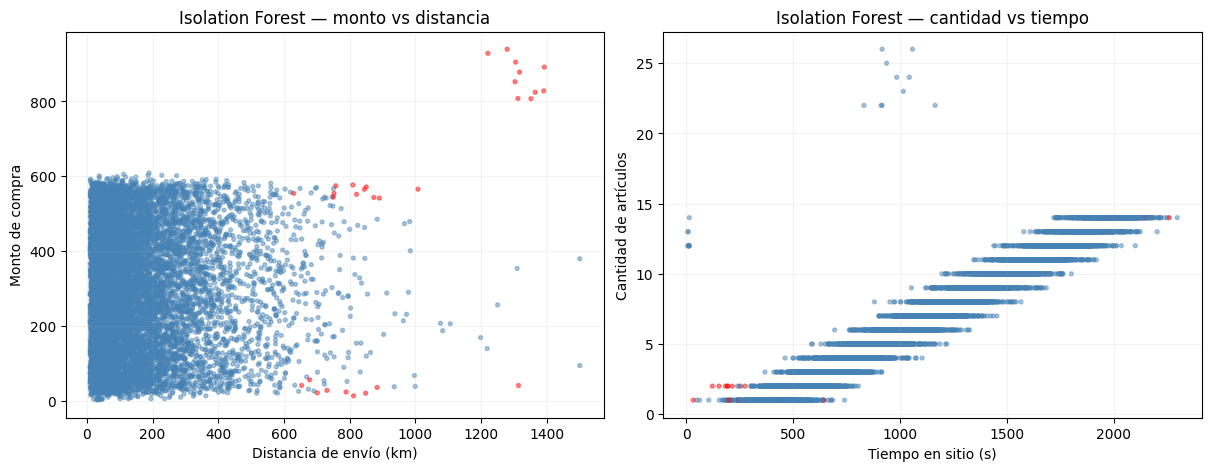

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained")
colores_iforest = np.where(df_ecommerce["iforest_Labels"].eq(1), "red", "steelblue")

axes[0].scatter(df_ecommerce["Distancia_Envio_Km"], df_ecommerce["Monto_Compra"],
                c=colores_iforest, s=8, alpha=0.45)
axes[0].set_title("Isolation Forest — monto vs distancia")
axes[0].set_xlabel("Distancia de envío (km)")
axes[0].set_ylabel("Monto de compra")

axes[1].scatter(df_ecommerce["Tiempo_En_Sitio_Seg"], df_ecommerce["Cantidad_Articulos"],
                c=colores_iforest, s=8, alpha=0.45)
axes[1].set_title("Isolation Forest — cantidad vs tiempo")
axes[1].set_xlabel("Tiempo en sitio (s)")
axes[1].set_ylabel("Cantidad de artículos")

for ax in axes:
    ax.grid(alpha=0.15)
plt.show()

## 3. Conclusión y comparación final

Los modelos **no** usaron las columnas de verdad para entrenar; las empleamos al final para evaluar detecciones reales, falsos positivos y falsos negativos. Un score de anomalía no equivale a una probabilidad de fraude.

En SaaS, LOF ayuda a no confundir automáticamente a los usuarios Enterprise legítimos con bots. En Ecommerce, Isolation Forest reconoce patrones extremos de triangulación, pero puede **no detectar fraudes contextuales** cuando se parecen a combinaciones habituales del conjunto. Esa limitación es un resultado importante de la práctica.

**Procedencia:** `class_anomalias.ipynb` (notebook de clase) + `saas_anomalias.csv` + `ecommerce.csv` (actividad oficial).

In [10]:
resumen = pd.DataFrame({
    "SaaS — LOF": resumen_saas,
    "Ecommerce — IForest": resumen_ecommerce,
})
print("--------- COMPARACIÓN FINAL ---------")
display(resumen)

for nombre, valores in [("SaaS", resumen_saas), ("Ecommerce", resumen_ecommerce)]:
    vp = valores["Verdaderos positivos"]
    fp = valores["Falsos positivos"]
    fn = valores["Falsos negativos"]
    precision = vp / (vp + fp) if vp + fp else 0
    recall = vp / (vp + fn) if vp + fn else 0
    print(f"{nombre}: precisión={precision:.1%}; sensibilidad={recall:.1%}")

print("\nResumen por categoría Ecommerce:")
display(resumen_categorias)

--------- COMPARACIÓN FINAL ---------


,SaaS — LOF,Ecommerce — IForest
Registros,10000,10000
Anomalías reales,21,30
Anomalías detectadas,21,30
Verdaderos positivos,19,10
Falsos positivos,2,20
Falsos negativos,2,20
Verdaderos negativos,9977,9950


SaaS: precisión=90.5%; sensibilidad=90.5%
Ecommerce: precisión=33.3%; sensibilidad=33.3%

Resumen por categoría Ecommerce:


,Reales,Detectados,No detectados
Etiqueta_Real,,,
Fraude_BotVeloz,10,0,10
Fraude_Cupones,10,0,10
Fraude_Triangulacion,10,10,0
